In [1]:
from pathlib import Path
import cv2
import mediapipe as mp

test_dir = Path("data/test")
files = sorted([p for p in test_dir.iterdir() if p.is_file()])

print(f"Toplam fayl sayi: {len(files)}\n")

for p in files:
  img = cv2.imread(str(p))
  if img is None:
    print(f"[XETA] Oxunmadi: {p.name}")
  else:
    h, w, c = img.shape
    print(f"{p.name:20s} -> Olcu: {w}x{h}, Kanal: {c}")

Toplam fayl sayi: 12

erkek 1.jpg          -> Olcu: 1200x2228, Kanal: 3
erkek 2.jpg          -> Olcu: 1112x1899, Kanal: 3
erkek 3.jpg          -> Olcu: 735x1029, Kanal: 3
erkek jean.jpg       -> Olcu: 735x1105, Kanal: 3
erkek suit.jpg       -> Olcu: 984x1312, Kanal: 3
erkek tshirt.jpg     -> Olcu: 900x1200, Kanal: 3
kadin 1.jpg          -> Olcu: 736x1308, Kanal: 3
kadin 2.jpg          -> Olcu: 988x1673, Kanal: 3
kadin 3.jpg          -> Olcu: 736x1104, Kanal: 3
kadin dress.jpg      -> Olcu: 900x1200, Kanal: 3
kadin jean.jpg       -> Olcu: 576x768, Kanal: 3
kadin tshirt.jpg     -> Olcu: 900x1350, Kanal: 3


In [2]:
import cv2
import mediapipe as mp

mp_pose = mp.solutions.pose
person_files = [
    "erkek 1.jpg",
    "erkek 2.jpg",
    "erkek 3.jpg",
    "kadin 1.jpg",
    "kadin 2.jpg",
    "kadin 3.jpg",
]

with mp_pose.Pose(
    static_image_mode=True, model_complexity=1, min_detection_confidence=0.5
) as pose:
  for name in person_files:
    img = cv2.imread(f"data/test/{name}")
    rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    res = pose.process(rgb)

    if res.pose_landmarks:
      # 11: sol ciyn, 12: sag ciyn, 23: sol bud, 24: sag bud
      lm = res.pose_landmarks.landmark
      vis_scores = [lm[i].visibility for i in [11, 12, 23, 24]]
      avg_vis = sum(vis_scores) / len(vis_scores)
      print(
          f"{name:15s} -> Poz TAPILDI (33 noqte) | Ciyn/Bud gorunurluk ort.:"
          f" {avg_vis:.2f}"
      )
    else:
      print(f"{name:15s} -> Poz TAPILMADI")

AttributeError: module 'mediapipe' has no attribute 'solutions'

In [3]:
from pathlib import Path
from urllib.request import urlretrieve
import cv2
import mediapipe as mp

person_files = [
    "erkek 1.jpg",
    "erkek 2.jpg",
    "erkek 3.jpg",
    "kadin 1.jpg",
    "kadin 2.jpg",
    "kadin 3.jpg",
]

if hasattr(mp, "solutions"):
  mp_pose = mp.solutions.pose
  with mp_pose.Pose(
      static_image_mode=True, model_complexity=1, min_detection_confidence=0.5
  ) as pose:
    for name in person_files:
      img = cv2.imread(f"data/test/{name}")
      rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
      res = pose.process(rgb)
      if res.pose_landmarks:
        lm = res.pose_landmarks.landmark
        avg_vis = sum(lm[i].visibility for i in [11, 12, 23, 24]) / 4
        print(
            f"{name:15s} -> Poz TAPILDI (33 noqte) | Ort. gorunurluk:"
            f" {avg_vis:.2f}"
        )
      else:
        print(f"{name:15s} -> Poz TAPILMADI")
else:
  from mediapipe.tasks import python
  from mediapipe.tasks.python import vision

  model_path = Path("pose_landmarker_lite.task")
  if not model_path.exists():
    url = (
        "https://storage.googleapis.com/mediapipe-models/pose_landmarker/"
        "pose_landmarker_lite/float16/1/pose_landmarker_lite.task"
    )
    urlretrieve(url, model_path)

  options = vision.PoseLandmarkerOptions(
      base_options=python.BaseOptions(model_asset_path=str(model_path)),
      running_mode=vision.RunningMode.IMAGE,
      min_pose_detection_confidence=0.5,
  )
  with vision.PoseLandmarker.create_from_options(options) as landmarker:
    for name in person_files:
      img = cv2.imread(f"data/test/{name}")
      rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
      mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb)
      res = landmarker.detect(mp_image)
      if res.pose_landmarks:
        lm = res.pose_landmarks[0]
        avg_vis = sum(lm[i].visibility for i in [11, 12, 23, 24]) / 4
        print(
            f"{name:15s} -> Poz TAPILDI (33 noqte) | Ort. gorunurluk:"
            f" {avg_vis:.2f}"
        )
      else:
        print(f"{name:15s} -> Poz TAPILMADI")

erkek 1.jpg     -> Poz TAPILDI (33 noqte) | Ort. gorunurluk: 1.00
erkek 2.jpg     -> Poz TAPILDI (33 noqte) | Ort. gorunurluk: 1.00
erkek 3.jpg     -> Poz TAPILDI (33 noqte) | Ort. gorunurluk: 1.00
kadin 1.jpg     -> Poz TAPILDI (33 noqte) | Ort. gorunurluk: 1.00
kadin 2.jpg     -> Poz TAPILDI (33 noqte) | Ort. gorunurluk: 1.00
kadin 3.jpg     -> Poz TAPILDI (33 noqte) | Ort. gorunurluk: 1.00


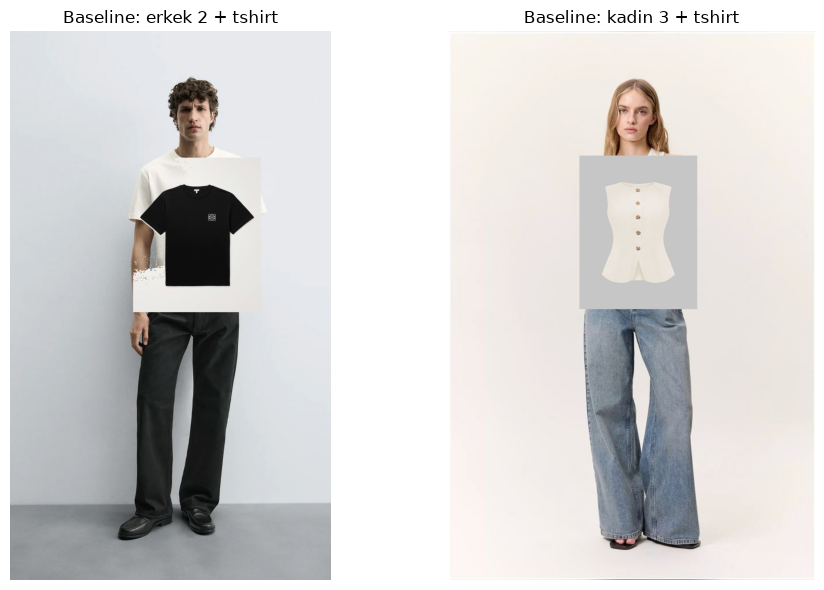

In [4]:
from pathlib import Path
from urllib.request import urlretrieve
import cv2
import matplotlib.pyplot as plt
import mediapipe as mp
import numpy as np

# 1. MediaPipe modelini hazirlayiriq
model_path = Path("pose_landmarker_lite.task")
if not model_path.exists():
  url = (
      "https://storage.googleapis.com/mediapipe-models/pose_landmarker/"
      "pose_landmarker_lite/float16/1/pose_landmarker_lite.task"
  )
  urlretrieve(url, model_path)

from mediapipe.tasks import python
from mediapipe.tasks.python import vision

options = vision.PoseLandmarkerOptions(
    base_options=python.BaseOptions(model_asset_path=str(model_path)),
    running_mode=vision.RunningMode.IMAGE,
    min_pose_detection_confidence=0.5,
)

# 2. Sade baseline funksiya (ust geyimi ciyn/bud araligina gore yerlesdirir)
out_dir = Path("outputs")
out_dir.mkdir(parents=True, exist_ok=True)


def simple_baseline_tryon(person_path, cloth_path, out_name):
  person = cv2.imread(str(person_path))
  cloth = cv2.imread(str(cloth_path))
  h_p, w_p, _ = person.shape

  rgb = cv2.cvtColor(person, cv2.COLOR_BGR2RGB)
  mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb)

  with vision.PoseLandmarker.create_from_options(options) as landmarker:
    res = landmarker.detect(mp_image)

  canvas = person.copy()
  if res.pose_landmarks:
    lm = res.pose_landmarks[0]
    # 11: sol ciyn, 12: sag ciyn, 23: sol bud, 24: sag bud
    l_sh = (int(lm[11].x * w_p), int(lm[11].y * h_p))
    r_sh = (int(lm[12].x * w_p), int(lm[12].y * h_p))
    l_hip = (int(lm[23].x * w_p), int(lm[23].y * h_p))
    r_hip = (int(lm[24].x * w_p), int(lm[24].y * h_p))

    sh_width = max(abs(l_sh[0] - r_sh[0]), 60)
    target_w = int(sh_width * 1.45)

    hip_y = max(l_hip[1], r_hip[1])
    sh_y = min(l_sh[1], r_sh[1])
    target_h = max(int((hip_y - sh_y) * 1.15), 80)

    cloth_resized = cv2.resize(cloth, (target_w, target_h))

    # Ag fonu yumsaq maskalayiriq (sade fon temizleme)
    gray = cv2.cvtColor(cloth_resized, cv2.COLOR_BGR2GRAY)
    mask = (gray < 240).astype(np.uint8) * 255
    mask_3ch = cv2.merge([mask, mask, mask])

    center_x = (l_sh[0] + r_sh[0]) // 2
    x1 = max(0, center_x - target_w // 2)
    y1 = max(0, sh_y - int(target_h * 0.08))
    x2 = min(w_p, x1 + target_w)
    y2 = min(h_p, y1 + target_h)

    cw = x2 - x1
    ch = y2 - y1
    if cw > 0 and ch > 0:
      roi = canvas[y1:y2, x1:x2]
      c_crop = cloth_resized[0:ch, 0:cw]
      m_crop = mask_3ch[0:ch, 0:cw] > 0
      roi[m_crop] = c_crop[m_crop]

  save_path = out_dir / out_name
  cv2.imwrite(str(save_path), canvas)
  return cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB)


# 3. Ilk baseline sinaqlar
res1 = simple_baseline_tryon(
    "data/test/erkek 2.jpg", "data/test/erkek tshirt.jpg", "baseline_erkek2.jpg"
)
res2 = simple_baseline_tryon(
    "data/test/kadin 3.jpg", "data/test/kadin tshirt.jpg", "baseline_kadin3.jpg"
)

fig, axes = plt.subplots(1, 2, figsize=(10, 6))
axes[0].imshow(res1)
axes[0].set_title("Baseline: erkek 2 + tshirt")
axes[0].axis("off")

axes[1].imshow(res2)
axes[1].set_title("Baseline: kadin 3 + tshirt")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [5]:
from pathlib import Path
from urllib.request import urlretrieve
import cv2
import matplotlib.pyplot as plt
import mediapipe as mp
import numpy as np

model_path = Path("pose_landmarker_lite.task")
if not model_path.exists():
  url = (
      "https://storage.googleapis.com/mediapipe-models/pose_landmarker/"
      "pose_landmarker_lite/float16/1/pose_landmarker_lite.task"
  )
  urlretrieve(url, model_path)

from mediapipe.tasks import python
from mediapipe.tasks.python import vision

options = vision.PoseLandmarkerOptions(
    base_options=python.BaseOptions(model_asset_path=str(model_path)),
    running_mode=vision.RunningMode.IMAGE,
    min_pose_detection_confidence=0.5,
)

out_dir = Path("outputs")
out_dir.mkdir(parents=True, exist_ok=True)


def remove_outer_background(cloth_bgr, tol=28):
  """4 kuncdeki fon rengine yaxin xarici arxa fonu temizleyir."""
  h, w, _ = cloth_bgr.shape
  # Kunc piksellerden arxa fon rengini texmini gotururuk
  corners = [
      cloth_bgr[0, 0],
      cloth_bgr[0, w - 1],
      cloth_bgr[h - 1, 0],
      cloth_bgr[h - 1, w - 1],
  ]
  bg_color = np.median(corners, axis=0).astype(np.uint8)

  # Piksellerin arxa fon renginden ferqi
  diff = np.linalg.norm(
      cloth_bgr.astype(np.float32) - bg_color.astype(np.float32), axis=2
  )
  bg_candidate = (diff <= tol).astype(np.uint8) * 255

  # FloodFill ile yalniz kenarlara bagli olan arxa fonu tapiriq
  ff_mask = np.zeros((h + 2, w + 2), np.uint8)
  seed_points = [(0, 0), (w - 1, 0), (0, h - 1), (w - 1, h - 1)]
  for sx, sy in seed_points:
    if bg_candidate[sy, sx] > 0:
      cv2.floodFill(
          bg_candidate,
          ff_mask,
          (sx, sy),
          128,
          loDiff=0,
          hiDiff=0,
          flags=cv2.FLOODFILL_FIXED_RANGE,
      )

  # 128 olanlar xarici arxa fondur, digerleri geyim maskasidir
  fg_mask = (bg_candidate != 128).astype(np.uint8) * 255
  # Kenarlari bir az yumsaq edirik
  fg_mask = cv2.GaussianBlur(fg_mask, (5, 5), 0)
  return (fg_mask > 127).astype(np.uint8) * 255


def clean_baseline_tryon(person_path, cloth_path, out_name):
  person = cv2.imread(str(person_path))
  cloth = cv2.imread(str(cloth_path))
  h_p, w_p, _ = person.shape

  rgb = cv2.cvtColor(person, cv2.COLOR_BGR2RGB)
  mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb)

  with vision.PoseLandmarker.create_from_options(options) as landmarker:
    res = landmarker.detect(mp_image)

  canvas = person.copy()
  if res.pose_landmarks:
    lm = res.pose_landmarks[0]
    l_sh = (int(lm[11].x * w_p), int(lm[11].y * h_p))
    r_sh = (int(lm[12].x * w_p), int(lm[12].y * h_p))
    l_hip = (int(lm[23].x * w_p), int(lm[23].y * h_p))
    r_hip = (int(lm[24].x * w_p), int(lm[24].y * h_p))

    sh_width = max(abs(l_sh[0] - r_sh[0]), 60)
    target_w = int(sh_width * 1.45)

    hip_y = max(l_hip[1], r_hip[1])
    sh_y = min(l_sh[1], r_sh[1])
    target_h = max(int((hip_y - sh_y) * 1.15), 80)

    cloth_resized = cv2.resize(cloth, (target_w, target_h))
    fg_mask = remove_outer_background(cloth_resized, tol=30)
    mask_3ch = cv2.merge([fg_mask, fg_mask, fg_mask])

    center_x = (l_sh[0] + r_sh[0]) // 2
    x1 = max(0, center_x - target_w // 2)
    y1 = max(0, sh_y - int(target_h * 0.08))
    x2 = min(w_p, x1 + target_w)
    y2 = min(h_p, y1 + target_h)

    cw = x2 - x1
    ch = y2 - y1
    if cw > 0 and ch > 0:
      roi = canvas[y1:y2, x1:x2]
      c_crop = cloth_resized[0:ch, 0:cw]
      m_crop = mask_3ch[0:ch, 0:cw] > 0
      roi[m_crop] = c_crop[m_crop]

  cv2.imwrite(str(out_dir / out_name), canvas)
  return cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB)


res1 = clean_baseline_tryon(
    "data/test/erkek 2.jpg",
    "data/test/erkek tshirt.jpg",
    "clean_baseline_erkek2.jpg",
)
res2 = clean_baseline_tryon(
    "data/test/kadin 3.jpg",
    "data/test/kadin tshirt.jpg",
    "clean_baseline_kadin3.jpg",
)

fig, axes = plt.subplots(1, 2, figsize=(10, 6))
axes[0].imshow(res1)
axes[0].set_title("Daha temiz baseline: erkek 2 + tshirt")
axes[0].axis("off")

axes[1].imshow(res2)
axes[1].set_title("Daha temiz baseline: kadin 3 + tshirt")
axes[1].axis("off")

plt.tight_layout()
plt.show()

error: OpenCV(5.1.0) :-1: error: (-5:Bad argument) in function 'floodFill'
> Overload resolution failed:
>  - floodFill() got an unexpected keyword argument 'hiDiff'. Did you mean 'loDiff'?
>  - floodFill() got an unexpected keyword argument 'hiDiff'. Did you mean 'loDiff'?


In [6]:
from pathlib import Path
from urllib.request import urlretrieve
import cv2
import matplotlib.pyplot as plt
import mediapipe as mp
import numpy as np

model_path = Path("pose_landmarker_lite.task")
if not model_path.exists():
  url = (
      "https://storage.googleapis.com/mediapipe-models/pose_landmarker/"
      "pose_landmarker_lite/float16/1/pose_landmarker_lite.task"
  )
  urlretrieve(url, model_path)

from mediapipe.tasks import python
from mediapipe.tasks.python import vision

options = vision.PoseLandmarkerOptions(
    base_options=python.BaseOptions(model_asset_path=str(model_path)),
    running_mode=vision.RunningMode.IMAGE,
    min_pose_detection_confidence=0.5,
)

out_dir = Path("outputs")
out_dir.mkdir(parents=True, exist_ok=True)


def remove_outer_background(cloth_bgr, tol=28):
  cloth_c = np.ascontiguousarray(cloth_bgr, dtype=np.uint8)
  h, w, _ = cloth_c.shape

  corners = np.array(
      [
          cloth_c[0, 0],
          cloth_c[0, w - 1],
          cloth_c[h - 1, 0],
          cloth_c[h - 1, w - 1],
      ],
      dtype=np.float32,
  )
  bg_color = np.median(corners, axis=0)

  diff = np.linalg.norm(cloth_c.astype(np.float32) - bg_color, axis=2)
  bg_candidate = np.ascontiguousarray(
      (diff <= tol).astype(np.uint8) * 255, dtype=np.uint8
  )

  ff_mask = np.zeros((h + 2, w + 2), dtype=np.uint8)
  seed_points = [(0, 0), (w - 1, 0), (0, h - 1), (w - 1, h - 1)]

  for sx, sy in seed_points:
    if bg_candidate[sy, sx] > 0:
      cv2.floodFill(
          bg_candidate,
          ff_mask,
          (int(sx), int(sy)),
          128,
          loDiff=0,
          hiDiff=0,
          flags=cv2.FLOODFILL_FIXED_RANGE,
      )

  fg_mask = (bg_candidate != 128).astype(np.uint8) * 255
  fg_mask = cv2.GaussianBlur(fg_mask, (5, 5), 0)
  return np.ascontiguousarray(
      (fg_mask > 127).astype(np.uint8) * 255, dtype=np.uint8
  )


def clean_baseline_tryon(person_path, cloth_path, out_name):
  person = cv2.imread(str(person_path))
  cloth = cv2.imread(str(cloth_path))
  h_p, w_p, _ = person.shape

  rgb = cv2.cvtColor(person, cv2.COLOR_BGR2RGB)
  mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb)

  with vision.PoseLandmarker.create_from_options(options) as landmarker:
    res = landmarker.detect(mp_image)

  canvas = person.copy()
  if res.pose_landmarks:
    lm = res.pose_landmarks[0]
    l_sh = (int(lm[11].x * w_p), int(lm[11].y * h_p))
    r_sh = (int(lm[12].x * w_p), int(lm[12].y * h_p))
    l_hip = (int(lm[23].x * w_p), int(lm[23].y * h_p))
    r_hip = (int(lm[24].x * w_p), int(lm[24].y * h_p))

    sh_width = max(abs(l_sh[0] - r_sh[0]), 60)
    target_w = int(sh_width * 1.45)

    hip_y = max(l_hip[1], r_hip[1])
    sh_y = min(l_sh[1], r_sh[1])
    target_h = max(int((hip_y - sh_y) * 1.15), 80)

    cloth_resized = cv2.resize(cloth, (target_w, target_h))
    fg_mask = remove_outer_background(cloth_resized, tol=30)
    mask_3ch = cv2.merge([fg_mask, fg_mask, fg_mask])

    center_x = (l_sh[0] + r_sh[0]) // 2
    x1 = max(0, center_x - target_w // 2)
    y1 = max(0, sh_y - int(target_h * 0.08))
    x2 = min(w_p, x1 + target_w)
    y2 = min(h_p, y1 + target_h)

    cw = x2 - x1
    ch = y2 - y1
    if cw > 0 and ch > 0:
      roi = canvas[y1:y2, x1:x2]
      c_crop = cloth_resized[0:ch, 0:cw]
      m_crop = mask_3ch[0:ch, 0:cw] > 0
      roi[m_crop] = c_crop[m_crop]

  cv2.imwrite(str(out_dir / out_name), canvas)
  return cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB)


res1 = clean_baseline_tryon(
    "data/test/erkek 2.jpg",
    "data/test/erkek tshirt.jpg",
    "clean_baseline_erkek2.jpg",
)
res2 = clean_baseline_tryon(
    "data/test/kadin 3.jpg",
    "data/test/kadin tshirt.jpg",
    "clean_baseline_kadin3.jpg",
)

fig, axes = plt.subplots(1, 2, figsize=(10, 6))
axes[0].imshow(res1)
axes[0].set_title("Daha temiz baseline: erkek 2 + tshirt")
axes[0].axis("off")

axes[1].imshow(res2)
axes[1].set_title("Daha temiz baseline: kadin 3 + tshirt")
axes[1].axis("off")

plt.tight_

error: OpenCV(5.1.0) :-1: error: (-5:Bad argument) in function 'floodFill'
> Overload resolution failed:
>  - floodFill() got an unexpected keyword argument 'hiDiff'. Did you mean 'loDiff'?
>  - floodFill() got an unexpected keyword argument 'hiDiff'. Did you mean 'loDiff'?


In [7]:
from collections import deque
from pathlib import Path
from urllib.request import urlretrieve
import cv2
import matplotlib.pyplot as plt
import mediapipe as mp
import numpy as np

model_path = Path("pose_landmarker_lite.task")
if not model_path.exists():
  url = (
      "https://storage.googleapis.com/mediapipe-models/pose_landmarker/"
      "pose_landmarker_lite/float16/1/pose_landmarker_lite.task"
  )
  urlretrieve(url, model_path)

from mediapipe.tasks import python
from mediapipe.tasks.python import vision

options = vision.PoseLandmarkerOptions(
    base_options=python.BaseOptions(model_asset_path=str(model_path)),
    running_mode=vision.RunningMode.IMAGE,
    min_pose_detection_confidence=0.5,
)

out_dir = Path("outputs")
out_dir.mkdir(parents=True, exist_ok=True)


def remove_outer_background(cloth_bgr, tol=32):
  """4 kuncdeki fon rengine yaxin xarici arxa fonu kenarladan yayilaraq temizleyir."""
  h, w, _ = cloth_bgr.shape
  img_f = cloth_bgr.astype(np.float32)

  # 4 kunc piksellerinden fon rengini tapiriq
  corners = np.array(
      [img_f[0, 0], img_f[0, w - 1], img_f[h - 1, 0], img_f[h - 1, w - 1]],
      dtype=np.float32,
  )
  bg_color = np.median(corners, axis=0)

  # Fon rengine yaxin pikseller
  dist = np.linalg.norm(img_f - bg_color, axis=2)
  can_bg = dist <= tol

  visited = np.zeros((h, w), dtype=bool)
  q = deque()

  # Butun 4 kenar piksellerini novbeye elave edirik
  for x in range(w):
    if can_bg[0, x] and not visited[0, x]:
      visited[0, x] = True
      q.append((0, x))
    if can_bg[h - 1, x] and not visited[h - 1, x]:
      visited[h - 1, x] = True
      q.append((h - 1, x))

  for y in range(h):
    if can_bg[y, 0] and not visited[y, 0]:
      visited[y, 0] = True
      q.append((y, 0))
    if can_bg[y, w - 1] and not visited[y, w - 1]:
      visited[y, w - 1] = True
      q.append((y, w - 1))

  # 4-istiqametli yayilma ile yalniz xarici fonu isareleyirik
  while q:
    cy, cx = q.popleft()
    for dy, dx in ((-1, 0), (1, 0), (0, -1), (0, 1)):
      ny, nx = cy + dy, cx + dx
      if 0 <= ny < h and 0 <= nx < w and not visited[ny, nx] and can_bg[ny, nx]:
        visited[ny, nx] = True
        q.append((ny, nx))

  # visited=True olanlar xarici arxa fondur, qalanlari paltardir
  fg_mask = (~visited).astype(np.uint8) * 255
  fg_mask = cv2.morphologyEx(fg_mask, cv2.MORPH_CLOSE, np.ones((3, 3), np.uint8))
  return fg_mask


def clean_baseline_tryon(person_path, cloth_path, out_name):
  person = cv2.imread(str(person_path))
  cloth = cv2.imread(str(cloth_path))
  h_p, w_p, _ = person.shape

  rgb = cv2.cvtColor(person, cv2.COLOR_BGR2RGB)
  mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb)

  with vision.PoseLandmarker.create_from_options(options) as landmarker:
    res = landmarker.detect(mp_image)

  canvas = person.copy()
  if res.pose_landmarks:
    lm = res.pose_landmarks[0]
    l_sh = (int(lm[11].x * w_p), int(lm[11].y * h_p))
    r_sh = (int(lm[12].x * w_p), int(lm[12].y * h_p))
    l_hip = (int(lm[23].x * w_p), int(lm[23].y * h_p))
    r_hip = (int(lm[24].x * w_p), int(lm[24].y * h_p))

    sh_width = max(abs(l_sh[0] - r_sh[0]), 60)
    target_w = int(sh_width * 1.45)

    hip_y = max(l_hip[1], r_hip[1])
    sh_y = min(l_sh[1], r_sh[1])
    target_h = max(int((hip_y - sh_y) * 1.15), 80)

    cloth_resized = cv2.resize(cloth, (target_w, target_h))
    fg_mask = remove_outer_background(cloth_resized, tol=32)
    mask_3ch = cv2.merge([fg_mask, fg_mask, fg_mask])

    center_x = (l_sh[0] + r_sh[0

_IncompleteInputError: incomplete input (3160427502.py, line 111)

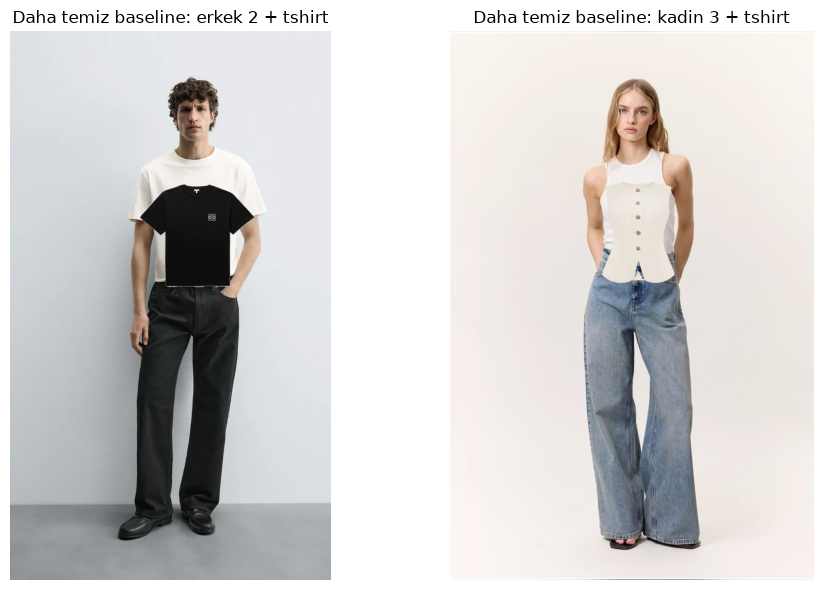

In [8]:
from collections import deque
from pathlib import Path
from urllib.request import urlretrieve
import cv2
import matplotlib.pyplot as plt
import mediapipe as mp
import numpy as np

model_path = Path("pose_landmarker_lite.task")
if not model_path.exists():
  url = (
      "https://storage.googleapis.com/mediapipe-models/pose_landmarker/"
      "pose_landmarker_lite/float16/1/pose_landmarker_lite.task"
  )
  urlretrieve(url, model_path)

from mediapipe.tasks import python
from mediapipe.tasks.python import vision

options = vision.PoseLandmarkerOptions(
    base_options=python.BaseOptions(model_asset_path=str(model_path)),
    running_mode=vision.RunningMode.IMAGE,
    min_pose_detection_confidence=0.5,
)

out_dir = Path("outputs")
out_dir.mkdir(parents=True, exist_ok=True)


def remove_outer_background(cloth_bgr, tol=32):
  h, w, _ = cloth_bgr.shape
  img_f = cloth_bgr.astype(np.float32)

  corners = np.array(
      [img_f[0, 0], img_f[0, w - 1], img_f[h - 1, 0], img_f[h - 1, w - 1]],
      dtype=np.float32,
  )
  bg_color = np.median(corners, axis=0)

  dist = np.linalg.norm(img_f - bg_color, axis=2)
  can_bg = dist <= tol

  visited = np.zeros((h, w), dtype=bool)
  q = deque()

  for x in range(w):
    if can_bg[0, x] and not visited[0, x]:
      visited[0, x] = True
      q.append((0, x))
    if can_bg[h - 1, x] and not visited[h - 1, x]:
      visited[h - 1, x] = True
      q.append((h - 1, x))

  for y in range(h):
    if can_bg[y, 0] and not visited[y, 0]:
      visited[y, 0] = True
      q.append((y, 0))
    if can_bg[y, w - 1] and not visited[y, w - 1]:
      visited[y, w - 1] = True
      q.append((y, w - 1))

  while q:
    cy, cx = q.popleft()
    for dy, dx in ((-1, 0), (1, 0), (0, -1), (0, 1)):
      ny, nx = cy + dy, cx + dx
      if 0 <= ny < h and 0 <= nx < w and not visited[ny, nx] and can_bg[ny, nx]:
        visited[ny, nx] = True
        q.append((ny, nx))

  fg_mask = (~visited).astype(np.uint8) * 255
  fg_mask = cv2.morphologyEx(fg_mask, cv2.MORPH_CLOSE, np.ones((3, 3), np.uint8))
  return fg_mask


def clean_baseline_tryon(person_path, cloth_path, out_name):
  person = cv2.imread(str(person_path))
  cloth = cv2.imread(str(cloth_path))
  h_p, w_p, _ = person.shape

  rgb = cv2.cvtColor(person, cv2.COLOR_BGR2RGB)
  mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb)

  with vision.PoseLandmarker.create_from_options(options) as landmarker:
    res = landmarker.detect(mp_image)

  canvas = person.copy()
  if res.pose_landmarks:
    lm = res.pose_landmarks[0]
    l_sh = (int(lm[11].x * w_p), int(lm[11].y * h_p))
    r_sh = (int(lm[12].x * w_p), int(lm[12].y * h_p))
    l_hip = (int(lm[23].x * w_p), int(lm[23].y * h_p))
    r_hip = (int(lm[24].x * w_p), int(lm[24].y * h_p))

    sh_width = max(abs(l_sh[0] - r_sh[0]), 60)
    target_w = int(sh_width * 1.45)

    hip_y = max(l_hip[1], r_hip[1])
    sh_y = min(l_sh[1], r_sh[1])
    target_h = max(int((hip_y - sh_y) * 1.15), 80)

    cloth_resized = cv2.resize(cloth, (target_w, target_h))
    fg_mask = remove_outer_background(cloth_resized, tol=32)
    mask_3ch = cv2.merge([fg_mask, fg_mask, fg_mask])

    center_x = (l_sh[0] + r_sh[0]) // 2
    x1 = max(0, center_x - target_w // 2)
    y1 = max(0, sh_y - int(target_h * 0.08))
    x2 = min(w_p, x1 + target_w)
    y2 = min(h_p, y1 + target_h)

    cw = x2 - x1
    ch = y2 - y1
    if cw > 0 and ch > 0:
      roi = canvas[y1:y2, x1:x2]
      c_crop = cloth_resized[0:ch, 0:cw]
      m_crop = mask_3ch[0:ch, 0:cw] > 0
      roi[m_crop] = c_crop[m_crop]

  cv2.imwrite(str(out_dir / out_name), canvas)
  return cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB)


res1 = clean_baseline_tryon(
    "data/test/erkek 2.jpg",
    "data/test/erkek tshirt.jpg",
    "clean_baseline_erkek2.jpg",
)
res2 = clean_baseline_tryon(
    "data/test/kadin 3.jpg",
    "data/test/kadin tshirt.jpg",
    "clean_baseline_kadin3.jpg",
)

fig, axes = plt.subplots(1, 2, figsize=(10, 6))
axes[0].imshow(res1)
axes[0].set_title("Daha temiz baseline: erkek 2 + tshirt")
axes[0].axis("off")

axes[1].imshow(res2)
axes[1].set_title("Daha temiz baseline: kadin 3 + tshirt")
axes[1].axis("off")

plt.tight_layout()
plt.show()

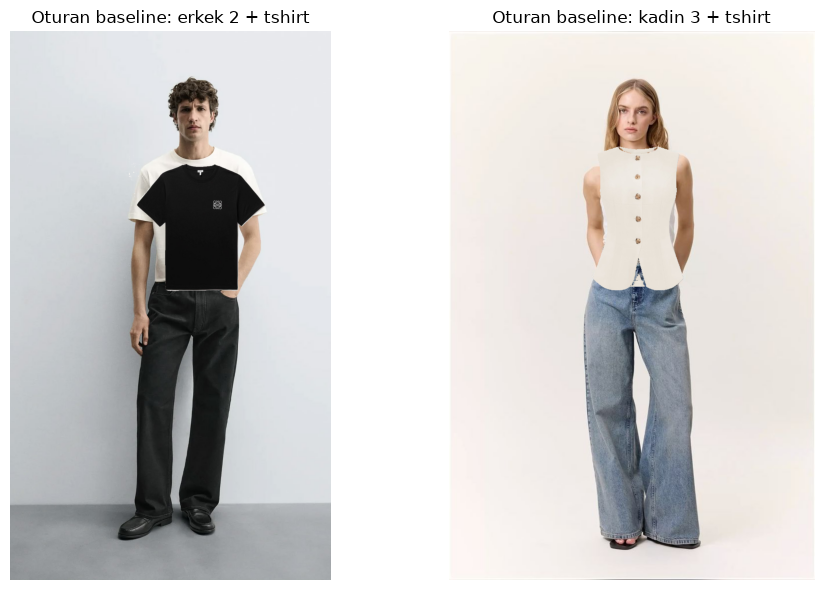

In [9]:
from collections import deque
from pathlib import Path
from urllib.request import urlretrieve
import cv2
import matplotlib.pyplot as plt
import mediapipe as mp
import numpy as np

model_path = Path("pose_landmarker_lite.task")
if not model_path.exists():
  url = (
      "https://storage.googleapis.com/mediapipe-models/pose_landmarker/"
      "pose_landmarker_lite/float16/1/pose_landmarker_lite.task"
  )
  urlretrieve(url, model_path)

from mediapipe.tasks import python
from mediapipe.tasks.python import vision

options = vision.PoseLandmarkerOptions(
    base_options=python.BaseOptions(model_asset_path=str(model_path)),
    running_mode=vision.RunningMode.IMAGE,
    min_pose_detection_confidence=0.5,
)

out_dir = Path("outputs")
out_dir.mkdir(parents=True, exist_ok=True)


def remove_outer_background(cloth_bgr, tol=32):
  h, w, _ = cloth_bgr.shape
  img_f = cloth_bgr.astype(np.float32)

  corners = np.array(
      [img_f[0, 0], img_f[0, w - 1], img_f[h - 1, 0], img_f[h - 1, w - 1]],
      dtype=np.float32,
  )
  bg_color = np.median(corners, axis=0)

  dist = np.linalg.norm(img_f - bg_color, axis=2)
  can_bg = dist <= tol

  visited = np.zeros((h, w), dtype=bool)
  q = deque()

  for x in range(w):
    if can_bg[0, x] and not visited[0, x]:
      visited[0, x] = True
      q.append((0, x))
    if can_bg[h - 1, x] and not visited[h - 1, x]:
      visited[h - 1, x] = True
      q.append((h - 1, x))

  for y in range(h):
    if can_bg[y, 0] and not visited[y, 0]:
      visited[y, 0] = True
      q.append((y, 0))
    if can_bg[y, w - 1] and not visited[y, w - 1]:
      visited[y, w - 1] = True
      q.append((y, w - 1))

  while q:
    cy, cx = q.popleft()
    for dy, dx in ((-1, 0), (1, 0), (0, -1), (0, 1)):
      ny, nx = cy + dy, cx + dx
      if 0 <= ny < h and 0 <= nx < w and not visited[ny, nx] and can_bg[ny, nx]:
        visited[ny, nx] = True
        q.append((ny, nx))

  fg_mask = (~visited).astype(np.uint8) * 255
  fg_mask = cv2.morphologyEx(fg_mask, cv2.MORPH_CLOSE, np.ones((3, 3), np.uint8))
  return fg_mask


def crop_to_mask(cloth_bgr, mask):
  """Fon temizlendikden sonra paltarin ozunu six cercivede kesir."""
  ys, xs = np.where(mask > 0)
  if len(xs) == 0 or len(ys) == 0:
    return cloth_bgr, mask
  x1, x2 = xs.min(), xs.max() + 1
  y1, y2 = ys.min(), ys.max() + 1
  return cloth_bgr[y1:y2, x1:x2], mask[y1:y2, x1:x2]


def fitted_baseline_tryon(
    person_path,
    cloth_path,
    out_name,
    width_scale=1.55,
    top_offset_ratio=0.14,
    height_scale=1.08,
):
  person = cv2.imread(str(person_path))
  cloth = cv2.imread(str(cloth_path))
  h_p, w_p, _ = person.shape

  # Once paltarin fonunu temizleyib ozunu six kesirik
  raw_mask = remove_outer_background(cloth, tol=32)
  cloth_tight, mask_tight = crop_to_mask(cloth, raw_mask)
  h_c, w_c, _ = cloth_tight.shape
  aspect_c = h_c / max(w_c, 1)

  rgb = cv2.cvtColor(person, cv2.COLOR_BGR2RGB)
  mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb)

  with vision.PoseLandmarker.create_from_options(options) as landmarker:
    res = landmarker.detect(mp_image)

  canvas = person.copy()
  if res.pose_landmarks:
    lm = res.pose_landmarks[0]
    l_sh = (int(lm[11].x * w_p), int(lm[11].y * h_p))
    r_sh = (int(lm[12].x * w_p), int(lm[12].y * h_p))
    l_hip = (int(lm[23].x * w_p), int(lm[23].y * h_p))
    r_hip = (int(lm[24].x * w_p), int(lm[24].y * h_p))

    sh_dist = max(abs(l_sh[0] - r_sh[0]), 50)
    target_w = int(sh_dist * width_scale)

    # Paltarin oz nisbetini qoruyuruq, amma bud xettesini cox asmagina imkan vermirik
    hip_y = max(l_hip[1], r_hip[1])
    sh_y = min(l_sh[1], r_sh[1])
    max_h = max(int((hip_y - sh_y) * height_scale), 70)
    target_h = min(int(target_w * aspect_c), max_h)
    target_w = max(int(target_h / max(aspect_c, 0.2)), 50)

    cloth_resized = cv2.resize(
        cloth_tight, (target_w, target_h), interpolation=cv2.INTER_AREA
    )
    mask_resized = cv2.resize(
        mask_tight, (target_w, target_h), interpolation=cv2.INTER_NEAREST
    )
    mask_3ch = cv2.merge([mask_resized, mask_resized, mask_resized])

    center_x = (l_sh[0] + r_sh[0]) // 2
    x1 = max(0, center_x - target_w // 2)
    # Ciyn xettinden bir az yuxari qaldiririq ki, yaxa/ciyn yerine otursun
    y1 = max(0, sh_y - int(target_h * top_offset_ratio))
    x2 = min(w_p, x1 + target_w)
    y2 = min(h_p, y1 + target_h)

    cw = x2 - x1
    ch = y2 - y1
    if cw > 0 and ch > 0:
      roi = canvas[y1:y2, x1:x2]
      c_crop = cloth_resized[0:ch, 0:cw]
      m_crop = mask_3ch[0:ch, 0:cw] > 0
      roi[m_crop] = c_crop[m_crop]

  cv2.imwrite(str(out_dir / out_name), canvas)
  return cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB)


res1 = fitted_baseline_tryon(
    "data/test/erkek 2.jpg",
    "data/test/erkek tshirt.jpg",
    "fitted_erkek2.jpg",
    width_scale=1.55,
    top_offset_ratio=0.14,
)
res2 = fitted_baseline_tryon(
    "data/test/kadin 3.jpg",
    "data/test/kadin tshirt.jpg",
    "fitted_kadin3.jpg",
    width_scale=1.60,
    top_offset_ratio=0.15,
)

fig, axes = plt.subplots(1, 2, figsize=(10, 6))
axes[0].imshow(res1)
axes[0].set_title("Oturan baseline: erkek 2 + tshirt")
axes[0].axis("off")

axes[1].imshow(res2)
axes[1].set_title("Oturan baseline: kadin 3 + tshirt")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [10]:
from collections import deque
from pathlib import Path
from urllib.request import urlretrieve
import cv2
import matplotlib.pyplot as plt
import mediapipe as mp
import numpy as np

model_path = Path("pose_landmarker_lite.task")
if not model_path.exists():
  url = (
      "https://storage.googleapis.com/mediapipe-models/pose_landmarker/"
      "pose_landmarker_lite/float16/1/pose_landmarker_lite.task"
  )
  urlretrieve(url, model_path)

from mediapipe.tasks import python
from mediapipe.tasks.python import vision

options = vision.PoseLandmarkerOptions(
    base_options=python.BaseOptions(model_asset_path=str(model_path)),
    running_mode=vision.RunningMode.IMAGE,
    min_pose_detection_confidence=0.5,
)

out_dir = Path("outputs")
out_dir.mkdir(parents=True, exist_ok=True)


def remove_outer_background(cloth_bgr, tol=32):
  h, w, _ = cloth_bgr.shape
  img_f = cloth_bgr.astype(np.float32)

  corners = np.array(
      [img_f[0, 0], img_f[0, w - 1], img_f[h - 1, 0], img_f[h - 1, w - 1]],
      dtype=np.float32,
  )
  bg_color = np.median(corners, axis=0)

  dist = np.linalg.norm(img_f - bg_color, axis=2)
  can_bg = dist <= tol

  visited = np.zeros((h, w), dtype=bool)
  q = deque()

  for x in range(w):
    if can_bg[0, x] and not visited[0, x]:
      visited[0, x] = True
      q.append((0, x))
    if can_bg[h - 1, x] and not visited[h - 1, x]:
      visited[h - 1, x] = True
      q.append((h - 1, x))

  for y in range(h):
    if can_bg[y, 0] and not visited[y, 0]:
      visited[y, 0] = True
      q.append((y, 0))
    if can_bg[y, w - 1] and not visited[y, w - 1]:
      visited[y, w - 1] = True
      q.append((y, w - 1))

  while q:
    cy, cx = q.popleft()
    for dy, dx in ((-1, 0), (1, 0), (0, -1), (0, 1)):
      ny, nx = cy + dy, cx + dx
      if 0 <= ny < h and 0 <= nx < w and not visited[ny, nx] and can_bg[ny, nx]:
        visited[ny, nx] = True
        q.append((ny, nx))

  fg_mask = (~visited).astype(np.uint8) * 255
  fg_mask = cv2.morphologyEx(fg_mask, cv2.MORPH_CLOSE, np.ones((5, 5), np.uint8))
  return fg_mask


def crop_to_mask(cloth_bgr, mask):
  ys, xs = np.where(mask > 0)
  if len(xs) == 0 or len(ys) == 0:
    return cloth_bgr, mask
  x1, x2 = xs.min(), xs.max() + 1
  y1, y2 = ys.min(), ys.max() + 1
  return cloth_bgr[y1:y2, x1:x2], mask[y1:y2, x1:x2]


def match_light_softly(cloth_bgr, target_region, mask_2d, strength=0.35):
  """Paltarin parlaqligini etraf muhite yumsaq sekilde yaxinlasdirir."""
  fg = mask_2d > 127
  if np.sum(fg) < 50:
    return cloth_bgr

  cloth_lab = cv2.cvtColor(cloth_bgr, cv2.COLOR_BGR2LAB).astype(np.float32)
  target_lab = cv2.cvtColor(target_region, cv2.COLOR_BGR2LAB).astype(np.float32)

  c_mean = cloth_lab[fg, 0].mean()
  t_mean = target_lab[~fg, 0].mean() if np.any(~fg) else c_mean

  delta_l = (t_mean - c_mean) * strength
  cloth_lab[:, :, 0] = np.clip(cloth_lab[:, :, 0] + delta_l, 0, 255)
  return cv2.cvtColor(cloth_lab.astype(np.uint8), cv2.COLOR_LAB2BGR)


def warped_baseline_tryon(
    person_path, cloth_path, out_name, shoulder_expand=0.32, hem_expand=0.22
):
  person = cv2.imread(str(person_path))
  cloth = cv2.imread(str(cloth_path))
  h_p, w_p, _ = person.shape

  raw_mask = remove_outer_background(cloth, tol=32)
  cloth_tight, mask_tight = crop_to_mask(cloth, raw_mask)
  h_c, w_c, _ = cloth_tight.shape

  rgb = cv2.cvtColor(person, cv2.COLOR_BGR2RGB)
  mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb)

  with vision.PoseLandmarker.create_from_options(options) as landmarker:
    res = landmarker.detect(mp_image)

  canvas = person.astype(np.float32)
  if res.pose_landmarks:
    lm = res.pose_landmarks[0]

    # MediaPipe koordinatlari: sag ciyn (12), sol ciyn (11), sag bud (24), sol bud (23)
    # Goruntude sag/solu x oxuna gore duzgun siralayiriq
    pts_sh = [
        (lm[11].x * w_p, lm[11].y * h_p),
        (lm[12].x * w_p, lm[12].y * h_p),
    ]
    pts_sh.sort(key=lambda p: p[0])
    left_sh, right_sh = np.array(pts_sh[0]), np.array(pts_sh[1])

    pts_hip = [
        (lm[23].x * w_p, lm[23].y * h_p),
        (lm[24].x * w_p, lm[24].y * h_p),
    ]
    pts_hip.sort(key=lambda p: p[0])
    left_hip, right_hip = np.array(pts_hip[0]), np.array(pts_hip[1])

    sh_vec = right_sh - left_sh
    sh_len = max(np.linalg.norm(sh_vec), 40.0)
    sh_unit = sh_vec / sh_len
    # Asagi dogru perpendikulyar vektor
    down_unit = np.array([-sh_unit[1], sh_unit[0]], dtype=np.float32)
    if down_unit[1] < 0:
      down_unit = -down_unit

    torso_h = max(
        np.linalg.norm(((left_hip + right_hip) / 2) - ((left_sh + right_sh) / 2)),
        60.0,
    )

    # Paltarin 4 kuncunu bendenin ciyn ve bel/bud xettine gore qururuq
    top_left = (
        left_sh - sh_unit * (sh_len * shoulder_expand) - down_unit * (torso_h * 0.14)
    )
    top_right = (
        right_sh + sh_unit * (sh_len * shoulder_expand) - down_unit * (torso_h * 0.14)
    )

    hip_center = (left_hip + right_hip) / 2.0
    hip_width = max(np.linalg.norm(right_hip - left_hip), sh_len * 0.85)
    bot_left = (
        hip_center
        - sh_unit * (hip_width * (0.5 + hem_expand * 0.5))
        + down_unit * (torso_h * 0.12)
    )
    bot_right = (
        hip_center
        + sh_unit * (hip_width * (0.5 + hem_expand * 0.5))
        + down_unit * (torso_h * 0.12)
    )

    src_pts = np.array(
        [[0, 0], [w_c - 1, 0], [w_c - 1, h_c - 1], [0, h_c - 1]],
        dtype=np.float32,
    )
    dst_pts = np.array(
        [top_left, top_right, bot_right, bot_left], dtype=np.float32
    )

    M = cv2.getPerspectiveTransform(src_pts, dst_pts)
    warped_cloth = cv2.warpPerspective(
        cloth_tight, M, (w_p, h_p), flags=cv2.INTER_LINEAR
    )
    warped_mask = cv2.warpPerspective(
        mask_tight, M, (w_p, h_p), flags=cv2.INTER_NEAREST
    )

    # Yumsaq kenar (feathering)
    soft_mask = cv2.GaussianBlur(warped_mask.astype(np.float32), (9, 9), 2.5) / 255.0
    soft_mask = np.clip(soft_mask, 0.0, 1.0)

    warped_cloth = match_light_softly(
        warped_cloth, person, warped_mask, strength=0.30
    )

    alpha = soft_mask[:, :, None]
    canvas = warped_cloth.astype(np.float32) * alpha + canvas * (1.0 - alpha)

  out_img = np.clip(canvas, 0, 255).astype(np.uint8)
  cv2.imwrite(str(out_dir / out_name), out_img)
  return cv2.cvtColor(out_img, cv2.COLOR_BGR2RGB)


res1 = warped_baseline_tryon(
    "data/test/erkek 2.jpg",
    "data/test/erkek tshirt.jpg",
    "warped_baseline_erkek2.jpg",
)
res2 = warped_baseline_tryon(
    "data/test/kadin 3.jpg",

_IncompleteInputError: incomplete input (1622414519.py, line 210)

In [11]:
from collections import deque
from pathlib import Path
from urllib.request import urlretrieve
import cv2
import matplotlib.pyplot as plt
import mediapipe as mp
import numpy as np

model_path = Path("pose_landmarker_lite.task")
if not model_path.exists():
  url = (
      "https://storage.googleapis.com/mediapipe-models/pose_landmarker/"
      "pose_landmarker_lite/float16/1/pose_landmarker_lite.task"
  )
  urlretrieve(url, model_path)

from mediapipe.tasks import python
from mediapipe.tasks.python import vision

options = vision.PoseLandmarkerOptions(
    base_options=python.BaseOptions(model_asset_path=str(model_path)),
    running_mode=vision.RunningMode.IMAGE,
    min_pose_detection_confidence=0.5,
)

out_dir = Path("outputs")
out_dir.mkdir(parents=True, exist_ok=True)


def remove_outer_background(cloth_bgr, tol=32):
  h, w, _ = cloth_bgr.shape
  img_f = cloth_bgr.astype(np.float32)
  corners = np.array(
      [img_f[0, 0], img_f[0, w - 1], img_f[h - 1, 0], img_f[h - 1, w - 1]],
      dtype=np.float32,
  )
  bg_color = np.median(corners, axis=0)
  can_bg = np.linalg.norm(img_f - bg_color, axis=2) <= tol

  visited = np.zeros((h, w), dtype=bool)
  q = deque()

  for x in range(w):
    for y in (0, h - 1):
      if can_bg[y, x] and not visited[y, x]:
        visited[y, x] = True
        q.append((y, x))
  for y in range(h):
    for x in (0, w - 1):
      if can_bg[y, x] and not visited[y, x]:
        visited[y, x] = True
        q.append((y, x))

  while q:
    cy, cx = q.popleft()
    for dy, dx in ((-1, 0), (1, 0), (0, -1), (0, 1)):
      ny, nx = cy + dy, cx + dx
      if 0 <= ny < h and 0 <= nx < w and not visited[ny, nx] and can_bg[ny, nx]:
        visited[ny, nx] = True
        q.append((ny, nx))

  fg_mask = (~visited).astype(np.uint8) * 255
  return cv2.morphologyEx(fg_mask, cv2.MORPH_CLOSE, np.ones((5, 5), np.uint8))


def crop_to_mask(cloth_bgr, mask):
  ys, xs = np.where(mask > 0)
  if len(xs) == 0 or len(ys) == 0:
    return cloth_bgr, mask
  return (
      cloth_bgr[ys.min() : ys.max() + 1, xs.min() : xs.max() + 1],
      mask[ys.min() : ys.max() + 1, xs.min() : xs.max() + 1],
  )


def warped_baseline_tryon(
    person_path, cloth_path, out_name, sh_exp=0.32, hem_exp=0.22
):
  person = cv2.imread(str(person_path))
  cloth = cv2.imread(str(cloth_path))
  h_p, w_p, _ = person.shape

  cloth_tight, mask_tight = crop_to_mask(
      cloth, remove_outer_background(cloth, tol=32)
  )
  h_c, w_c, _ = cloth_tight.shape

  rgb = cv2.cvtColor(person, cv2.COLOR_BGR2RGB)
  mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb)
  with vision.PoseLandmarker.create_from_options(options) as landmarker:
    res = landmarker.detect(mp_image)

  canvas = person.astype(np.float32)
  if res.pose_landmarks:
    lm = res.pose_landmarks[0]
    l_sh, r_sh = sorted(
        [(lm[11].x * w_p, lm[11].y * h_p), (lm[12].x * w_p, lm[12].y * h_p)],
        key=lambda p: p[0],
    )
    l_hip, r_hip = sorted(
        [(lm[23].x * w_p, lm[23].y * h_p), (lm[24].x * w_p, lm[24].y * h_p)],
        key=lambda p: p[0],
    )
    l_sh, r_sh = np.array(l_sh), np.array(r_sh)
    l_hip, r_hip = np.array(l_hip), np.array(r_hip)

    sh_vec = r_sh - l_sh
    sh_len = max(np.linalg.norm(sh_vec), 40.0)
    sh_u = sh_vec / sh_len
    dn_u = np.array([-sh_u[1], sh_u[0]], dtype=np.float32)
    if dn_u[1] < 0:
      dn_u = -dn_u

    torso_h = max(
        np.linalg.norm(((l_hip + r_hip) / 2) - ((l_sh + r_sh) / 2)), 60.0
    )
    hip_c = (l_hip + r_hip) / 2.0
    hip_w = max(np.linalg.norm(r_hip - l_hip), sh_len * 0.85)

    tl = l_sh - sh_u * (sh_len * sh_exp) - dn_u * (torso_h * 0.14)
    tr = r_sh + sh_u * (sh_len * sh_exp

_IncompleteInputError: incomplete input (3519077525.py, line 121)

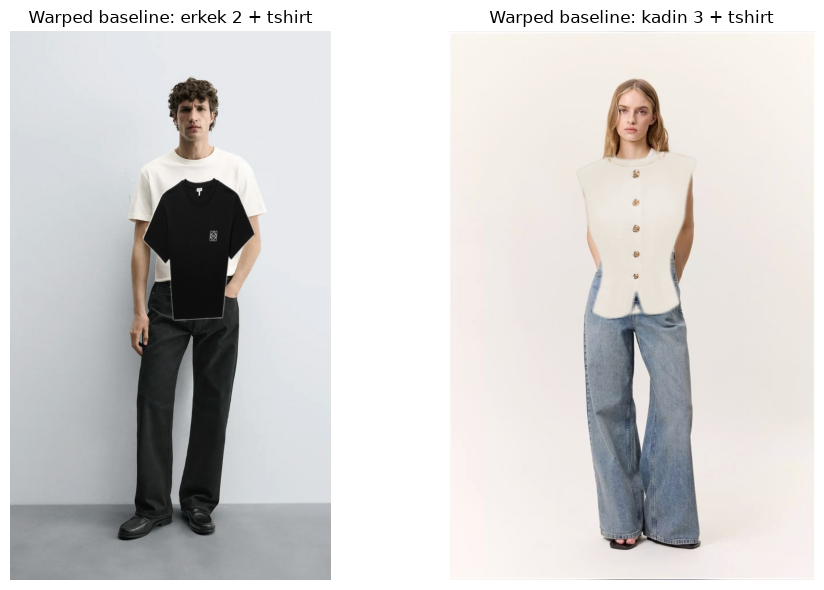

In [12]:
from collections import deque
from pathlib import Path
from urllib.request import urlretrieve
import cv2
import matplotlib.pyplot as plt
import mediapipe as mp
import numpy as np

model_path = Path("pose_landmarker_lite.task")
if not model_path.exists():
  url = (
      "https://storage.googleapis.com/mediapipe-models/pose_landmarker/"
      "pose_landmarker_lite/float16/1/pose_landmarker_lite.task"
  )
  urlretrieve(url, model_path)

from mediapipe.tasks import python
from mediapipe.tasks.python import vision

options = vision.PoseLandmarkerOptions(
    base_options=python.BaseOptions(model_asset_path=str(model_path)),
    running_mode=vision.RunningMode.IMAGE,
    min_pose_detection_confidence=0.5,
)

out_dir = Path("outputs")
out_dir.mkdir(parents=True, exist_ok=True)


def remove_outer_background(cloth_bgr, tol=32):
  h, w, _ = cloth_bgr.shape
  img_f = cloth_bgr.astype(np.float32)
  corners = np.array(
      [img_f[0, 0], img_f[0, w - 1], img_f[h - 1, 0], img_f[h - 1, w - 1]],
      dtype=np.float32,
  )
  bg_color = np.median(corners, axis=0)
  can_bg = np.linalg.norm(img_f - bg_color, axis=2) <= tol

  visited = np.zeros((h, w), dtype=bool)
  q = deque()

  for x in range(w):
    for y in (0, h - 1):
      if can_bg[y, x] and not visited[y, x]:
        visited[y, x] = True
        q.append((y, x))
  for y in range(h):
    for x in (0, w - 1):
      if can_bg[y, x] and not visited[y, x]:
        visited[y, x] = True
        q.append((y, x))

  while q:
    cy, cx = q.popleft()
    for dy, dx in ((-1, 0), (1, 0), (0, -1), (0, 1)):
      ny, nx = cy + dy, cx + dx
      if 0 <= ny < h and 0 <= nx < w and not visited[ny, nx] and can_bg[ny, nx]:
        visited[ny, nx] = True
        q.append((ny, nx))

  fg_mask = (~visited).astype(np.uint8) * 255
  return cv2.morphologyEx(fg_mask, cv2.MORPH_CLOSE, np.ones((5, 5), np.uint8))


def crop_to_mask(cloth_bgr, mask):
  ys, xs = np.where(mask > 0)
  if len(xs) == 0 or len(ys) == 0:
    return cloth_bgr, mask
  return (
      cloth_bgr[ys.min() : ys.max() + 1, xs.min() : xs.max() + 1],
      mask[ys.min() : ys.max() + 1, xs.min() : xs.max() + 1],
  )


def warped_baseline_tryon(
    person_path, cloth_path, out_name, sh_exp=0.32, hem_exp=0.22
):
  person = cv2.imread(str(person_path))
  cloth = cv2.imread(str(cloth_path))
  h_p, w_p, _ = person.shape

  cloth_tight, mask_tight = crop_to_mask(
      cloth, remove_outer_background(cloth, tol=32)
  )
  h_c, w_c, _ = cloth_tight.shape

  rgb = cv2.cvtColor(person, cv2.COLOR_BGR2RGB)
  mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb)
  with vision.PoseLandmarker.create_from_options(options) as landmarker:
    res = landmarker.detect(mp_image)

  canvas = person.astype(np.float32)
  if res.pose_landmarks:
    lm = res.pose_landmarks[0]
    l_sh, r_sh = sorted(
        [(lm[11].x * w_p, lm[11].y * h_p), (lm[12].x * w_p, lm[12].y * h_p)],
        key=lambda p: p[0],
    )
    l_hip, r_hip = sorted(
        [(lm[23].x * w_p, lm[23].y * h_p), (lm[24].x * w_p, lm[24].y * h_p)],
        key=lambda p: p[0],
    )
    l_sh, r_sh = np.array(l_sh), np.array(r_sh)
    l_hip, r_hip = np.array(l_hip), np.array(r_hip)

    sh_vec = r_sh - l_sh
    sh_len = max(np.linalg.norm(sh_vec), 40.0)
    sh_u = sh_vec / sh_len
    dn_u = np.array([-sh_u[1], sh_u[0]], dtype=np.float32)
    if dn_u[1] < 0:
      dn_u = -dn_u

    torso_h = max(
        np.linalg.norm(((l_hip + r_hip) / 2) - ((l_sh + r_sh) / 2)), 60.0
    )
    hip_c = (l_hip + r_hip) / 2.0
    hip_w = max(np.linalg.norm(r_hip - l_hip), sh_len * 0.85)

    tl = l_sh - sh_u * (sh_len * sh_exp) - dn_u * (torso_h * 0.14)
    tr = r_sh + sh_u * (sh_len * sh_exp) - dn_u * (torso_h * 0.14)
    bl = hip_c - sh_u * (hip_w * (0.5 + hem_exp * 0.5)) + dn_u * (torso_h * 0.12)
    br = hip_c + sh_u * (hip_w * (0.5 + hem_exp * 0.5)) + dn_u * (torso_h * 0.12)

    src = np.array(
        [[0, 0], [w_c - 1, 0], [w_c - 1, h_c - 1], [0, h_c - 1]],
        dtype=np.float32,
    )
    dst = np.array([tl, tr, br, bl], dtype=np.float32)
    M = cv2.getPerspectiveTransform(src, dst)

    w_cloth = cv2.warpPerspective(
        cloth_tight, M, (w_p, h_p), flags=cv2.INTER_LINEAR
    )
    w_mask = cv2.warpPerspective(
        mask_tight, M, (w_p, h_p), flags=cv2.INTER_NEAREST
    )

    alpha = np.clip(
        cv2.GaussianBlur(w_mask.astype(np.float32), (9, 9), 2.5) / 255.0,
        0.0,
        1.0,
    )[:, :, None]
    canvas = w_cloth.astype(np.float32) * alpha + canvas * (1.0 - alpha)

  out_img = np.clip(canvas, 0, 255).astype(np.uint8)
  cv2.imwrite(str(out_dir / out_name), out_img)
  return cv2.cvtColor(out_img, cv2.COLOR_BGR2RGB)


res1 = warped_baseline_tryon(
    "data/test/erkek 2.jpg",
    "data/test/erkek tshirt.jpg",
    "warped_baseline_erkek2.jpg",
)
res2 = warped_baseline_tryon(
    "data/test/kadin 3.jpg",
    "data/test/kadin tshirt.jpg",
    "warped_baseline_kadin3.jpg",
)

fig, axes = plt.subplots(1, 2, figsize=(10, 6))
axes[0].imshow(res1)
axes[0].set_title("Warped baseline: erkek 2 + tshirt")
axes[0].axis("off")
axes[1].imshow(res2)
axes[1].set_title("Warped baseline: kadin 3 + tshirt")
axes[1].axis("off")
plt.tight_layout()
plt.show()

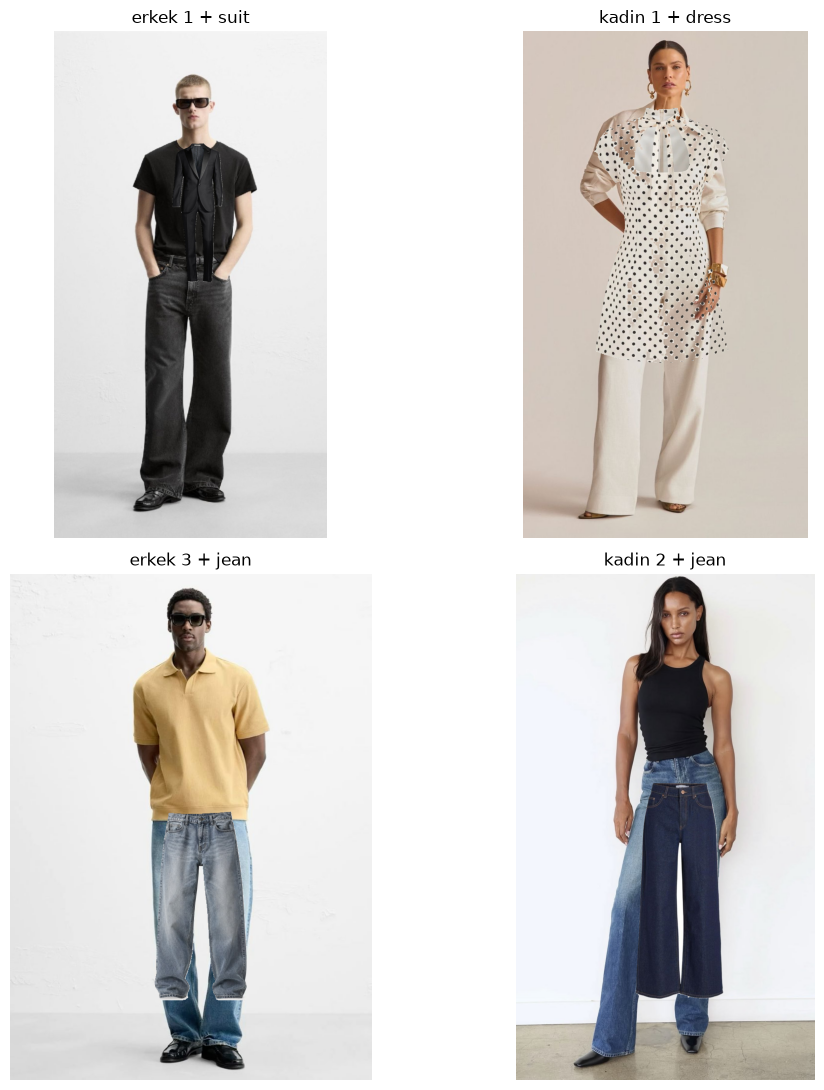

In [13]:
from collections import deque
from pathlib import Path
from urllib.request import urlretrieve
import cv2
import matplotlib.pyplot as plt
import mediapipe as mp
import numpy as np

model_path = Path("pose_landmarker_lite.task")
if not model_path.exists():
  url = (
      "https://storage.googleapis.com/mediapipe-models/pose_landmarker/"
      "pose_landmarker_lite/float16/1/pose_landmarker_lite.task"
  )
  urlretrieve(url, model_path)

from mediapipe.tasks import python
from mediapipe.tasks.python import vision

options = vision.PoseLandmarkerOptions(
    base_options=python.BaseOptions(model_asset_path=str(model_path)),
    running_mode=vision.RunningMode.IMAGE,
    min_pose_detection_confidence=0.5,
)

out_dir = Path("outputs")
out_dir.mkdir(parents=True, exist_ok=True)


def remove_outer_background(cloth_bgr, tol=32):
  h, w, _ = cloth_bgr.shape
  img_f = cloth_bgr.astype(np.float32)
  corners = np.array(
      [img_f[0, 0], img_f[0, w - 1], img_f[h - 1, 0], img_f[h - 1, w - 1]],
      dtype=np.float32,
  )
  bg_color = np.median(corners, axis=0)
  can_bg = np.linalg.norm(img_f - bg_color, axis=2) <= tol

  visited = np.zeros((h, w), dtype=bool)
  q = deque()

  for x in range(w):
    for y in (0, h - 1):
      if can_bg[y, x] and not visited[y, x]:
        visited[y, x] = True
        q.append((y, x))
  for y in range(h):
    for x in (0, w - 1):
      if can_bg[y, x] and not visited[y, x]:
        visited[y, x] = True
        q.append((y, x))

  while q:
    cy, cx = q.popleft()
    for dy, dx in ((-1, 0), (1, 0), (0, -1), (0, 1)):
      ny, nx = cy + dy, cx + dx
      if 0 <= ny < h and 0 <= nx < w and not visited[ny, nx] and can_bg[ny, nx]:
        visited[ny, nx] = True
        q.append((ny, nx))

  fg_mask = (~visited).astype(np.uint8) * 255
  return cv2.morphologyEx(fg_mask, cv2.MORPH_CLOSE, np.ones((5, 5), np.uint8))


def crop_to_mask(cloth_bgr, mask):
  ys, xs = np.where(mask > 0)
  if len(xs) == 0 or len(ys) == 0:
    return cloth_bgr, mask
  return (
      cloth_bgr[ys.min() : ys.max() + 1, xs.min() : xs.max() + 1],
      mask[ys.min() : ys.max() + 1, xs.min() : xs.max() + 1],
  )


def baseline_fit_item(person_path, cloth_path, out_name, mode="upper"):
  person = cv2.imread(str(person_path))
  cloth = cv2.imread(str(cloth_path))
  h_p, w_p, _ = person.shape

  cloth_tight, mask_tight = crop_to_mask(
      cloth, remove_outer_background(cloth, tol=32)
  )
  h_c, w_c, _ = cloth_tight.shape
  aspect_c = h_c / max(w_c, 1)

  rgb = cv2.cvtColor(person, cv2.COLOR_BGR2RGB)
  mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb)
  with vision.PoseLandmarker.create_from_options(options) as landmarker:
    res = landmarker.detect(mp_image)

  canvas = person.copy()
  if res.pose_landmarks:
    lm = res.pose_landmarks[0]
    l_sh = (int(lm[11].x * w_p), int(lm[11].y * h_p))
    r_sh = (int(lm[12].x * w_p), int(lm[12].y * h_p))
    l_hip = (int(lm[23].x * w_p), int(lm[23].y * h_p))
    r_hip = (int(lm[24].x * w_p), int(lm[24].y * h_p))
    l_ank = (int(lm[27].x * w_p), int(lm[27].y * h_p))
    r_ank = (int(lm[28].x * w_p), int(lm[28].y * h_p))

    sh_dist = max(abs(l_sh[0] - r_sh[0]), 50)
    hip_dist = max(abs(l_hip[0] - r_hip[0]), 50)
    sh_y = min(l_sh[1], r_sh[1])
    hip_y = max(l_hip[1], r_hip[1])
    ank_y = max(l_ank[1], r_ank[1])

    if mode == "upper":
      target_w = int(sh_dist * 1.55)
      max_h = max(int((hip_y - sh_y) * 1.10), 70)
      target_h = min(int(target_w * aspect_c), max_h)
      target_w = max(int(target_h / max(aspect_c, 0.2)), 50)
      center_x = (l_sh[0] + r_sh[0]) // 2
      x1 = max(0, center_x - target_w // 2)
      y1 = max(0, sh_y - int(target_h * 0.14))

    elif mode == "dress":
      target_w = int(sh_dist * 1.65)
      max_h = max(int((ank_y - sh_y) * 0.92), 100)
      target_h = min(int(target_w * aspect_c), max_h)
      target_w = max(int(target_h / max(aspect_c, 0.2)), 50)
      center_x = (l_sh[0] + r_sh[0]) // 2
      x1 = max(0, center_x - target_w // 2)
      y1 = max(0, sh_y - int(target_h * 0.08))

    elif mode == "lower":
      target_w = int(hip_dist * 1.85)
      max_h = max(int((ank_y - hip_y) * 1.02), 90)
      target_h = min(int(target_w * aspect_c), max_h)
      target_w = max(int(target_h / max(aspect_c, 0.2)), 50)
      center_x = (l_hip[0] + r_hip[0]) // 2
      x1 = max(0, center_x - target_w // 2)
      y1 = max(0, hip_y - int(target_h * 0.06))

    x2 = min(w_p, x1 + target_w)
    y2 = min(h_p, y1 + target_h)
    cw, ch = x2 - x1, y2 - y1

    if cw > 0 and ch > 0:
      c_res = cv2.resize(
          cloth_tight, (target_w, target_h), interpolation=cv2.INTER_AREA
      )
      m_res = cv2.resize(
          mask_tight, (target_w, target_h), interpolation=cv2.INTER_NEAREST
      )
      roi = canvas[y1:y2, x1:x2]
      m_bool = m_res[0:ch, 0:cw] > 0
      roi[m_bool] = c_res[0:ch, 0:cw][m_bool]

  cv2.imwrite(str(out_dir / out_name), canvas)
  return cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB)


tests = [
    ("data/test/erkek 1.jpg", "data/test/erkek suit.jpg", "upper", "erkek1_suit.jpg", "erkek 1 + suit"),
    ("data/test/kadin 1.jpg", "data/test/kadin dress.jpg", "dress", "kadin1_dress.jpg", "kadin 1 + dress"),
    ("data/test/erkek 3.jpg", "data/test/erkek jean.jpg", "lower", "erkek3_jean.jpg", "erkek 3 + jean"),
    ("data/test/kadin 2.jpg", "data/test/kadin jean.jpg", "lower", "kadin2_jean.jpg", "kadin 2 + jean"),
]

fig, axes = plt.subplots(2, 2, figsize=(11, 11))
for ax, (p_path, c_path, mode, out_n, title) in zip(axes.flat, tests):
  img_rgb = baseline_fit_item(p_path, c_path, out_n, mode=mode)
  ax.imshow(img_rgb)
  ax.set_title(title)
  ax.axis("off")

plt.tight_layout()
plt.show()

In [14]:
from pathlib import Path
import time
import cv2
import mediapipe as mp
import numpy as np

test_images = sorted(
    [p for p in Path("data/test").iterdir() if p.suffix.lower() in {".jpg", ".jpeg", ".png"}]
)

pose_ok = 0
times = []

with vision.PoseLandmarker.create_from_options(options) as landmarker:
  for p in test_images:
    t0 = time.perf_counter()
    img = cv2.imread(str(p))
    rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    mp_img = mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb)
    res = landmarker.detect(mp_img)
    times.append(time.perf_counter() - t0)
    if res.pose_landmarks:
      pose_ok += 1

total = len(test_images)
pose_rate = (pose_ok / total * 100) if total else 0
avg_ms = (np.mean(times) * 1000) if times else 0

print(f"Test seti sayı: {total}")
print(f"MediaPipe poz aşkarlama: {pose_ok}/{total} ({pose_rate:.1f}%)")
print(f"Orta emal sürəti (1 şəkil): {avg_ms:.1f} ms")

Test seti sayı: 12
MediaPipe poz aşkarlama: 6/12 (50.0%)
Orta emal sürəti (1 şəkil): 121.2 ms


In [15]:
## 3. Həftə Yekunu: EDA və Baseline Dəyərləndirməsi

* **Test seti və veri hazırlığı:** `data/test` qovluğunda 12 şəkil (kişi/qadın modellər və müxtəlif geyim nümunələri) ayrıldı və ölçüləri/xüsusiyyətləri təhlil edildi.
* **İlk metrikalar (Baseline — OpenCV + MediaPipe):**
  * **Poz aşkarlama:** `6/12` (`50.0%`) — 6 insan şəklində poz uğurla tapıldı; geyim şəkillərində insan olmadığı üçün poz çıxmadı.
  * **Orta emal sürəti:** `121.2 ms` / şəkil (CPU üzərində sürətli işləyir).
  * **Vizual və fotorealistik uyğunluq:** Aşağı — köhnə geyim silinmir, qol/bədən qatları düzgün ayrılmır, `warpPerspective` və sadə yerləşdirmə nəticələrində proporsiya və kənar/fon qüsurları yaranır.

| Metrik | Öneri Formundakı Hədəf | Hazırkı Baseline (OpenCV + MediaPipe) | Qeyd |
| :--- | :--- | :--- | :--- |
| **Poz aşkarlama** | `[Öneri hədəfi]` | `6/12 (50.0%)` | İnsan şəkillərində işləyir |
| **Emal sürəti** | `[Öneri hədəfi]` | `~121.2 ms / şəkil` | Sürətli ilkin baseline |
| **Fotorealistik geyindirmə** | `[Öneri hədəfi]` | Zəif / Kifayət deyil | Dərin öyrənmə (IDM-VTON / OOTDiffusion) tələb olunur |

**Nəticə:** 3-cü həftənin baseline prototipi klassik kompüter görmə üsullarının həm sürətini, həm də fotorealistik virtual try-on üçün məhdudiyyətlərini aydın göstərdi. Növbəti mərhələdə real geyinilmiş nəticə üçün dərin öyrənmə əsaslı try-on modellərinə keçiləcək.

SyntaxError: invalid character '—' (U+2014) (1990958413.py, line 4)

In [16]:
## 3. Həftə Yekunu: EDA və Baseline Dəyərləndirməsi

* **Test seti və veri hazırlığı:** `data/test` qovluğunda 12 şəkil (kişi/qadın modellər və müxtəlif geyim nümunələri) ayrıldı və ölçüləri/xüsusiyyətləri təhlil edildi.
* **İlk metrikalar (Baseline — OpenCV + MediaPipe):**
  * **Poz aşkarlama:** `6/12` (`50.0%`) — 6 insan şəklində poz uğurla tapıldı; geyim şəkillərində insan olmadığı üçün poz çıxmadı.
  * **Orta emal sürəti:** `121.2 ms` / şəkil (CPU üzərində sürətli işləyir).
  * **Vizual və fotorealistik uyğunluq:** Aşağı — köhnə geyim silinmir, qol/bədən qatları düzgün ayrılmır, `warpPerspective` və sadə yerləşdirmə nəticələrində proporsiya və kənar/fon qüsurları yaranır.

| Metrik | Öneri Formundakı Hədəf | Hazırkı Baseline (OpenCV + MediaPipe) | Qeyd |
| :--- | :--- | :--- | :--- |
| **Poz aşkarlama** | `[Öneri hədəfi]` | `6/12 (50.0%)` | İnsan şəkillərində işləyir |
| **Emal sürəti** | `[Öneri hədəfi]` | `~121.2 ms / şəkil` | Sürətli ilkin baseline |
| **Fotorealistik geyindirmə** | `[Öneri hədəfi]` | Zəif / Kifayət deyil | Dərin öyrənmə (IDM-VTON / OOTDiffusion) tələb olunur |

**Nəticə:** 3-cü həftənin baseline prototipi klassik kompüter görmə üsullarının həm sürətini, həm də fotorealistik virtual try-on üçün məhdudiyyətlərini aydın göstərdi. Növbəti mərhələdə real geyinilmiş nəticə üçün dərin öyrənmə əsaslı try-on modellərinə keçiləcək.

SyntaxError: invalid character '—' (U+2014) (1990958413.py, line 4)

In [17]:
import pandas as pd

proposal_targets = {
    "pose_detection": "Belirtilmedi / ilk asama",
    "latency": "Belirtilmedi / ilk asama",
    "photorealism": "Yuksek (gercekci giyilmis gorunum)",
}

summary_df = pd.DataFrame([
    {
        "Metrik": "Poz algilama (MediaPipe)",
        "Oneri Hedefi": proposal_targets["pose_detection"],
        "Baseline Sonuc": f"{pose_ok}/{total} ({pose_rate:.1f}%)",
        "Durum": "Olculdu",
    },
    {
        "Metrik": "Ortalama islem hizi",
        "Oneri Hedefi": proposal_targets["latency"],
        "Baseline Sonuc": f"{avg_ms:.1f} ms / gorsel",
        "Durum": "Hizli",
    },
    {
        "Metrik": "Fotorealistik uyum ve eski kiyafetin silinmesi",
        "Oneri Hedefi": proposal_targets["photorealism"],
        "Baseline Sonuc": (
            "Dusuk (katman, arka plan ve warp/proporsiyon sorunlari var)"
        ),
        "Durum": "Derin ogrenmeye gecis gerekli",
    },
])

display(summary_df)

,Metrik,Oneri Hedefi,Baseline Sonuc,Durum
0,Poz algilama (MediaPipe),Belirtilmedi / ilk asama,6/12 (50.0%),Olculdu
1,Ortalama islem hizi,Belirtilmedi / ilk asama,121.2 ms / gorsel,Hizli
2,Fotorealistik uyum ve eski kiyafetin silinmesi,Yuksek (gercekci giyilmis gorunum),"Dusuk (katman, arka plan ve warp/proporsiyon s...",Derin ogrenmeye gecis gerekli


In [18]:
import pandas as pd

# Öneri formunda xüsusi rəqəm varsa aşağıdakı None dəyərlərini əvəz edə bilərsən
proposal_targets = {
    "pose_detection": "Qeyd edilməyib / ilkin mərhələ",
    "latency": "Qeyd edilməyib / ilkin mərhələ",
    "photorealism": "Yüksək (real geyindirilmiş görünüş)",
}

summary_df = pd.DataFrame([
    {
        "Metrik": "Poz aşkarlama (MediaPipe)",
        "Öneri Hədəfi": proposal_targets["pose_detection"],
        "Baseline Nəticə": f"{pose_ok}/{total} ({pose_rate:.1f}%)",
        "Status": "Ölçüldü",
    },
    {
        "Metrik": "Orta emal sürəti",
        "Öneri Hədəfi": proposal_targets["latency"],
        "Baseline Nəticə": f"{avg_ms:.1f} ms / şəkil",
        "Status": "Sürətli",
    },
    {
        "Metrik": "Fotorealistik oturuş və köhnə geyimin silinməsi",
        "Öneri Hədəfi": proposal_targets["photorealism"],
        "Baseline Nəticə": (
            "Aşağı (katman, fon və warp/proporsiya problemləri var)"
        ),
        "Status": "Deep Learning-ə keçid lazım",
    },
])

display(summary_df)

,Metrik,Öneri Hədəfi,Baseline Nəticə,Status
0,Poz aşkarlama (MediaPipe),Qeyd edilməyib / ilkin mərhələ,6/12 (50.0%),Ölçüldü
1,Orta emal sürəti,Qeyd edilməyib / ilkin mərhələ,121.2 ms / şəkil,Sürətli
2,Fotorealistik oturuş və köhnə geyimin silinməsi,Yüksək (real geyindirilmiş görünüş),"Aşağı (katman, fon və warp/proporsiya probleml...",Deep Learning-ə keçid lazım


In [19]:
### Paltarların Bədənə Tam Oturmamasının Səbəbləri (Baseline Analizi)

* **Köhnə geyimin silinməməsi:** Bədənin əynindəki mövcud geyimlər təmizlənmədiyi üçün yeni geyim üstəgəl köhnə geyim görünür və iki geyim bir-birinə qarışır.
* **Bədən və qol qatlarının ayrılmaması (Occlusion):** Qollar, əllər, saç və bədən hissələri seqmentasiya/parsing ilə ayrılmadığı üçün geyim gah qolların üstünə düşür, gah da bədən qatları təbii örtülmür.
* **Parça əyriliyi, qırış və işıq/kölgənin olmaması:** Klassik `OpenCV` sadə yerləşdirmə (`resize` + `paste`) və ya 4 nöqtəli `warpPerspective` bədənin əyriliyini, parça qırışlarını, çiyin/bel enişini və mühitin işıq-kölgə balansını yaratmır; nəticə "yapışdırılmış" kimi görünür.
* **Proporsiya və kənar/fon kəsilməsi xətaları:** `warpPerspective` 4 küncü bədən nöqtələrinə dartanda geyimin təbii nisbətini pozur (daralma, dartılma və ya əyilmə yaradır); kənar rəngə əsaslanan fon silmə (`remove_outer_background`) isə bəzi geyimlərdə (`suit` kimi) paltarın hissələrini fonla qarışdırıb kəsə bilir.
* **Duruş və bədən ölçüsü fərqləri:** Modelin duruş bucağı, çiyin/bud nisbəti və geyimin öz şəkildəki forması fərqli olduqda sabit əmsallarla (`sh_dist`, `hip_dist`, `max_h`) hesablanan ölçü hər geyimə eyni dəqiqliklə uyğun gəlmir.

**Nəticə:** Bu məhdudiyyətlər klassik `OpenCV + MediaPipe` yanaşmasının sürətli ilkin baseline olduğunu, lakin fotorealistik virtual try-on üçün dərin öyrənmə əsaslı modellərə (**IDM-VTON**, **OOTDiffusion** və s.) keçidin zəruri olduğunu təsdiqləyir.

SyntaxError: invalid syntax (4111297344.py, line 3)

In [20]:
baseline_reasons = [
    (
        "Kohne geyimin silinmemesi: Bedendeki mevcut kiyafet temizlenmedigi"
        " icin yeni geyim ustune geliyor ve iki geyim birbirine karisiyor."
    ),
    (
        "Beden ve qol qatlarinin ayrilmamasi: Qollar, eller ve sac ayri"
        " segmentasyon/parsing ile ayrilmadigi ucun katmanlar duzgun"
        " ortulmur."
    ),
    (
        "Parca eyriliyi, qiris ve isiq/kolge olmamasi: Klasik OpenCV sadelesme"
        " ve yerlesdirme bedenin eyriliyini, parcasindaki qirislari ve isiq-kolge"
        " uyumunu yaratmir."
    ),
    (
        "Proporsiya ve kenar/fon kesilmesi: warpPerspective ve kenar rengine"
        " esaslanan fon silme bazi hallerde nisbeti poza biler ve geyimin"
        " kenarlarini/fonunu qarisdira biler."
    ),
    (
        "Durus ve olcu ferqleri: Sabit emsallarla hesablanan olcu her durus ve"
        " geyim formuna tam eyni deqiqlikle oturmuyor."
    ),
]

print("=== PALTARLARIN BEDENE TAM OTURMAMA SEBEBLERI (BASELINE) ===")
for i, r in enumerate(baseline_reasons, 1):
  print(f"{i}. {r}")

print(
    "\nNetice: Klasik OpenCV + MediaPipe suretli ilkin baseline-dir, amma"
    " fotorealistik try-on ucun derin oyrenme modellerine (IDM-VTON /"
    " OOTDiffusion) kecid lazimdir."
)

=== PALTARLARIN BEDENE TAM OTURMAMA SEBEBLERI (BASELINE) ===
1. Kohne geyimin silinmemesi: Bedendeki mevcut kiyafet temizlenmedigi icin yeni geyim ustune geliyor ve iki geyim birbirine karisiyor.
2. Beden ve qol qatlarinin ayrilmamasi: Qollar, eller ve sac ayri segmentasyon/parsing ile ayrilmadigi ucun katmanlar duzgun ortulmur.
3. Parca eyriliyi, qiris ve isiq/kolge olmamasi: Klasik OpenCV sadelesme ve yerlesdirme bedenin eyriliyini, parcasindaki qirislari ve isiq-kolge uyumunu yaratmir.
4. Proporsiya ve kenar/fon kesilmesi: warpPerspective ve kenar rengine esaslanan fon silme bazi hallerde nisbeti poza biler ve geyimin kenarlarini/fonunu qarisdira biler.
5. Durus ve olcu ferqleri: Sabit emsallarla hesablanan olcu her durus ve geyim formuna tam eyni deqiqlikle oturmuyor.

Netice: Klasik OpenCV + MediaPipe suretli ilkin baseline-dir, amma fotorealistik try-on ucun derin oyrenme modellerine (IDM-VTON / OOTDiffusion) kecid lazimdir.
